### Q1 Which brain area has the lowest firing rate over the entire recording?

SUA data is loaded from dataset/unit_metadata.csv, firing rate is calculated and stored to fr.csv for stats in R. Descriptive plot is generated with FR per area and mean + 95% CI (without accounting for multiple units for the same mouse). For the results reporting, mean and CI from the stats model is used.

In [3]:
import numpy as np
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
project_folder = Path("E:/con2phys_submission/")
csv_path = project_folder / "dataset" / "unit_metadata.csv"
q_path = project_folder / "questions" / "q1"

METADATA_COLUMNS = [
    "mouse_id",
    "cluster_id",
    "brain_area",
    "recording_duration_sec",
    "unit_last_spike_sec",
    "n_spikes",
]
fr_df = pd.read_csv(csv_path, usecols=METADATA_COLUMNS)
fr_df["fr_hz"] = fr_df["n_spikes"] / fr_df["recording_duration_sec"]

fr_df.to_csv(q_path / "fr.csv")
print(f"Loaded {len(fr_df)} units from {fr_df['mouse_id'].nunique()} mice")
fr_df.head()

Loaded 1449 units from 18 mice


,mouse_id,cluster_id,brain_area,recording_duration_sec,unit_last_spike_sec,n_spikes,fr_hz
0,1,383,1,3350.972,3347.139344,14747,4.400813
1,1,386,1,3350.972,3347.725646,21102,6.297277
2,1,388,1,3350.972,3347.842001,27012,8.060945
3,1,389,1,3350.972,3345.364815,7535,2.248601
4,1,391,1,3350.972,1538.713336,9683,2.889609


In [6]:
q1_summary = (fr_df.groupby("brain_area")["fr_hz"].agg(mean_fr_hz="mean", sd_fr_hz="std", n_units="count"))
q1_summary["sem_fr_hz"] = (q1_summary["sd_fr_hz"] / np.sqrt(q1_summary["n_units"]))
q1_summary["ci95_margin_hz"] = 1.96 * q1_summary["sem_fr_hz"]
q1_summary["ci95_low_hz"] = (q1_summary["mean_fr_hz"] - q1_summary["ci95_margin_hz"])
q1_summary["ci95_high_hz"] = (q1_summary["mean_fr_hz"] + q1_summary["ci95_margin_hz"])
q1_summary.to_csv(q_path / "fr_mean_and_95_ci_no_stats.csv")
q1_summary

,mean_fr_hz,sd_fr_hz,n_units,sem_fr_hz,ci95_margin_hz,ci95_low_hz,ci95_high_hz
brain_area,,,,,,,
1,7.778995,5.944011,649,0.233323,0.457313,7.321682,8.236308
2,5.729482,6.255332,478,0.286112,0.560780,5.168702,6.290262
3,6.772304,6.520882,322,0.363395,0.712253,6.060050,7.484557


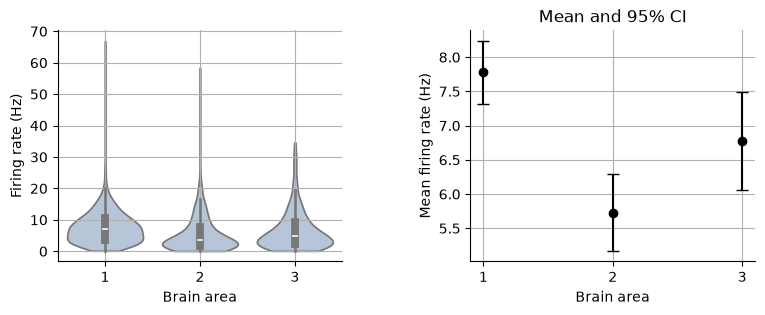

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3))
plt.subplots_adjust(wspace=0.45)

sns.violinplot(
    ax=axes[0], x="brain_area", y="fr_hz",
    data=fr_df, cut=0, density_norm="width",
    color="lightsteelblue")
axes[0].set_xlabel("Brain area")
axes[0].set_ylabel("Firing rate (Hz)")
axes[0].grid(True, linestyle='-')

areas = q1_summary.index.to_numpy()
means = q1_summary["mean_fr_hz"].to_numpy()
ci95 = q1_summary["ci95_margin_hz"].to_numpy()
axes[1].errorbar(
    areas, means, yerr=ci95,
    fmt="o", color="black", markersize=6,
    capsize=4, linewidth=1.5,
)
axes[1].set_xticks(areas)
axes[1].set_xlabel("Brain area")
axes[1].set_ylabel("Mean firing rate (Hz)")
axes[1].set_title("Mean and 95% CI")
axes[1].grid(True, linestyle='-')

sns.despine()

figure_path = q_path / "fr_mean_and_95_ci_no_stats.png"
fig.savefig(figure_path, dpi=150, bbox_inches="tight")